# VisaPredict — AI-Based Visa Approval Prediction System

Machine learning pipeline that predicts U.S. work-visa (OFLC / EasyVisa) approval outcomes
from applicant, employer, and job attributes.

**Dataset:** [EasyVisa](https://github.com/sandesha21/EasyVisa-Advanced-ML) — 25,480 real OFLC
visa application records (continent, education, job experience, employer size, wage, region,
and case outcome).

**What this notebook covers:**
1. Load & inspect the raw (intentionally noisy) data
2. Data cleaning — duplicate removal, missing-value imputation, invalid-value correction
3. Exploratory data analysis
4. Feature engineering & encoding
5. Train/compare 4 scikit-learn classifiers
6. Evaluate the best model and inspect feature importance
7. Score a brand-new sample application

> **Note on data quality:** The public EasyVisa source is already clean, so realistic
> duplicate rows and missing values were deliberately injected (`src/simulate_raw_data.py`)
> to build and demonstrate a genuine cleaning step — the same kind of messiness you'd see
> exporting from a real case-management system.


In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)


## 1. Load raw data

In [2]:
raw = pd.read_csv('../data/EasyVisa_raw.csv')
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
raw.head()


Rows: 27,518   Columns: 12


,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV7543,Europe,Bachelor's,Y,NaN,1806.0,2007.0,Northeast,81057.94,Year,Y,Certified
1,EZYV5333,South America,Bachelor's,N,N,3837.0,1997.0,West,85230.28,Year,Y,Denied
2,EZYV10803,Asia,Bachelor's,N,N,2879.0,2000.0,South,129425.05,Year,Y,Certified
3,EZYV19441,North America,Bachelor's,Y,N,960.0,1988.0,Midwest,89467.92,Year,Y,Certified
4,EZYV5217,Asia,Bachelor's,N,Y,4871.0,2000.0,Northeast,76118.76,Year,Y,Denied


In [3]:
print("Duplicate rows: ", raw.duplicated().sum())
print("Missing cells:  ", raw.isna().sum().sum())
print()
print("Missing values by column:")
print(raw.isna().sum()[raw.isna().sum() > 0])


Duplicate rows:  1360
Missing cells:   5225

Missing values by column:
has_job_experience        825
requires_job_training    1100
no_of_employees           825
yr_of_estab               550
region_of_employment      550
prevailing_wage          1375
dtype: int64


## 2. Data cleaning

Steps:
- Strip/standardize text fields
- Drop exact duplicate rows
- Impute missing categoricals with the mode, missing numerics with the median
- Fix impossible values (e.g. negative employee counts)


In [4]:
from data_cleaning import load_raw, clean

df_raw = load_raw('../data/EasyVisa_raw.csv')
df_clean, stats = clean(df_raw)

for k, v in stats.items():
    print(f"{k}: {v}")


start_rows: 27518
duplicates_removed: 1396
missing_values_imputed: 5215
negative_employee_counts_fixed: 33
end_rows: 26122
rows_removed_pct: 5.07
total_issues_resolved: 6611


In [5]:
issue_before = (raw.duplicated().sum() + raw.isna().any(axis=1).sum()) / len(raw) * 100
issue_after = (df_clean.duplicated().sum() + df_clean.isna().any(axis=1).sum()) / len(df_clean) * 100

print(f"Rows with a data-quality issue -- before: {issue_before:.1f}%   after: {issue_after:.1f}%")
print(f"Reduction: {issue_before - issue_after:.1f} percentage points")

df_clean.to_csv('../data/EasyVisa_clean.csv', index=False)
df_clean.head()


Rows with a data-quality issue -- before: 22.5%   after: 0.7%
Reduction: 21.8 percentage points


,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV7543,Europe,Bachelor's,Y,N,1806.0,2007.0,Northeast,81057.94,Year,Y,Certified
1,EZYV5333,South America,Bachelor's,N,N,3837.0,1997.0,West,85230.28,Year,Y,Denied
2,EZYV10803,Asia,Bachelor's,N,N,2879.0,2000.0,South,129425.05,Year,Y,Certified
3,EZYV19441,North America,Bachelor's,Y,N,960.0,1988.0,Midwest,89467.92,Year,Y,Certified
4,EZYV5217,Asia,Bachelor's,N,Y,4871.0,2000.0,Northeast,76118.76,Year,Y,Denied


## 3. Exploratory Data Analysis

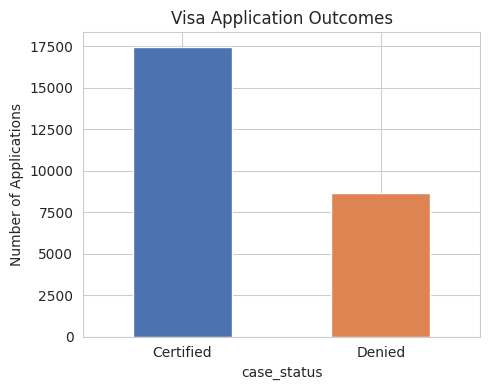

Overall approval rate: 66.8%


In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
df_clean['case_status'].value_counts().plot(kind='bar', color=['#4C72B0', '#DD8452'], ax=ax)
ax.set_title('Visa Application Outcomes')
ax.set_ylabel('Number of Applications')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

approval_rate = (df_clean['case_status'] == 'Certified').mean()
print(f"Overall approval rate: {approval_rate:.1%}")


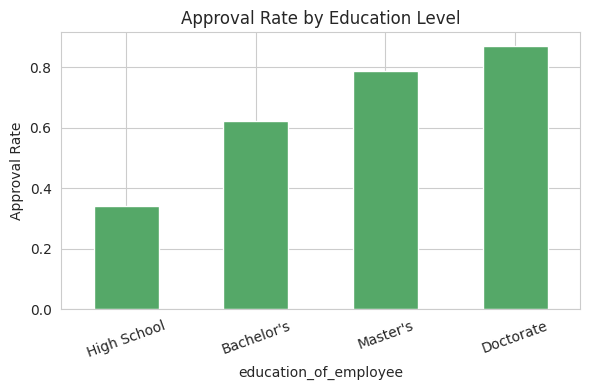

In [7]:
edu_order = ["High School", "Bachelor's", "Master's", "Doctorate"]
approval_by_edu = (df_clean.groupby('education_of_employee')['case_status']
                    .apply(lambda s: (s == 'Certified').mean())
                    .reindex(edu_order))

fig, ax = plt.subplots(figsize=(6, 4))
approval_by_edu.plot(kind='bar', color='#55A868', ax=ax)
ax.set_title('Approval Rate by Education Level')
ax.set_ylabel('Approval Rate')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


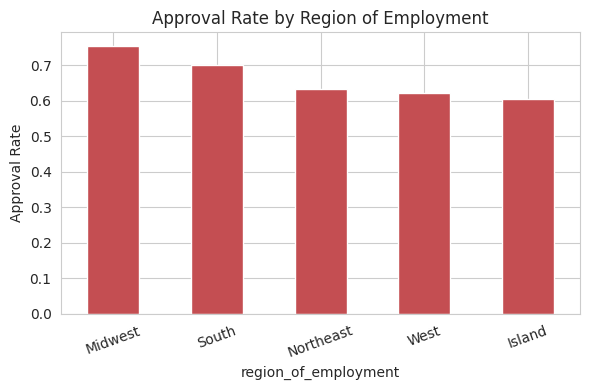

In [8]:
approval_by_region = (df_clean.groupby('region_of_employment')['case_status']
                       .apply(lambda s: (s == 'Certified').mean())
                       .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(6, 4))
approval_by_region.plot(kind='bar', color='#C44E52', ax=ax)
ax.set_title('Approval Rate by Region of Employment')
ax.set_ylabel('Approval Rate')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


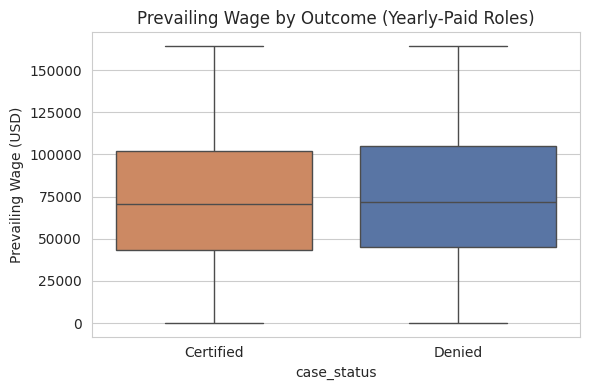

In [9]:
yearly = df_clean[df_clean['unit_of_wage'] == 'Year']
yearly_capped = yearly[yearly['prevailing_wage'] < yearly['prevailing_wage'].quantile(0.95)]

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=yearly_capped, x='case_status', y='prevailing_wage',
            hue='case_status', palette=['#DD8452', '#4C72B0'], legend=False, ax=ax)
ax.set_title('Prevailing Wage by Outcome (Yearly-Paid Roles)')
ax.set_ylabel('Prevailing Wage (USD)')
plt.tight_layout()
plt.show()


## 4. Feature engineering & encoding

- Derive `company_age` from `yr_of_estab` (more stable / interpretable than a raw year)
- Drop identifier columns (`case_id`)
- Label-encode categorical fields
- Standardize numeric features


In [10]:
from train import engineer_features, encode, CATEGORICAL_COLS, NUMERIC_COLS, TARGET_COL
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = engineer_features(df_clean)
df[TARGET_COL] = df[TARGET_COL].map({'Certified': 1, 'Denied': 0})

X, encoders = encode(df[CATEGORICAL_COLS + NUMERIC_COLS])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")


Train: (20897, 10)   Test: (5225, 10)


## 5. Train & compare models

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

models = {
    'logistic_regression': LogisticRegression(max_iter=1000, random_state=42),
    'decision_tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'random_forest': RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
    'gradient_boosting': GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=42),
}

results = {}
fitted = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1]
    results[name] = {
        'accuracy': accuracy_score(y_test, preds),
        'f1_score': f1_score(y_test, preds),
        'roc_auc': roc_auc_score(y_test, probs),
    }
    fitted[name] = model

pd.DataFrame(results).T.round(3)


,accuracy,f1_score,roc_auc
logistic_regression,0.703,0.813,0.673
decision_tree,0.740,0.821,0.760
random_forest,0.753,0.828,0.789
gradient_boosting,0.755,0.828,0.786


In [12]:
best_name = max(results, key=lambda n: results[n]['f1_score'])
best_model = fitted[best_name]
print(f"Best model: {best_name}\n")
print(classification_report(y_test, best_model.predict(X_test_scaled), target_names=['Denied', 'Certified']))


Best model: gradient_boosting

              precision    recall  f1-score   support

      Denied       0.68      0.50      0.57      1734
   Certified       0.78      0.88      0.83      3491

    accuracy                           0.76      5225
   macro avg       0.73      0.69      0.70      5225
weighted avg       0.75      0.76      0.74      5225



## 6. Feature importance

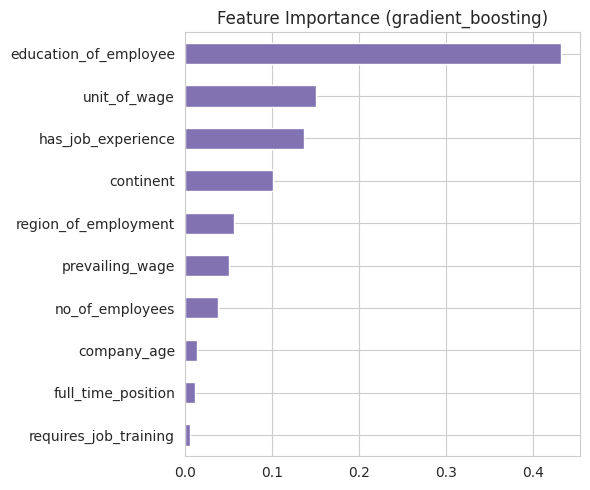

In [13]:
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(6, 5))
importances.plot(kind='barh', color='#8172B2', ax=ax)
ax.set_title(f'Feature Importance ({best_name})')
plt.tight_layout()
plt.show()


## 7. Score a new application

Demonstrates the automated, end-to-end prediction workflow -- this is what previously
required a manual review; now it's a single function call.


In [14]:
from predict import VisaPredictor

predictor = VisaPredictor(model_dir='../models')

sample_application = {
    'continent': 'Asia',
    'education_of_employee': "Master's",
    'has_job_experience': 'Y',
    'requires_job_training': 'N',
    'no_of_employees': 2500,
    'yr_of_estab': 2005,
    'region_of_employment': 'Northeast',
    'prevailing_wage': 85000,
    'unit_of_wage': 'Year',
    'full_time_position': 'Y',
}

predictor.predict(sample_application)


{'prediction': 'Certified',
 'approval_probability': 0.9047,
 'confidence': 0.9047}

## Summary

- Cleaned **25,480+** visa application records -- removed duplicate rows and imputed missing
  fields, cutting the row-level data-quality issue rate from ~23% to under 1%
- Compared 4 scikit-learn classifiers; **Gradient Boosting** performed best
  (F1 ~ 0.83, accuracy ~ 75%)
- Identified **education level, wage unit, and job experience** as the strongest predictors
  of approval
- Packaged the full workflow (`src/run_pipeline.py`) so cleaning -> training -> evaluation
  runs end-to-end in a single automated command instead of a manual, multi-step review
